# Pronóstico mensual del IPAP BMC

El modelo ETS usa hasta 120 meses recientes y pronostica doce meses completos. El CSV conserva 189 observaciones oficiales. Seguiremos los datos, el entrenamiento, la evaluación y el modelo guardado. Los períodos ya se examinaron durante el desarrollo, de modo que la evaluación es retrospectiva.


In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from modelo_ipap import (BASE, VENTANA, cargar_datos, pronosticar, evaluar, metricas,
                         guardar_modelo, cargar_modelo, pronostico_guardado, graficar)
plt.rcParams.update({"font.family":"Arial", "font.size":10})


## Leer los datos

Cada fila representa un mes. fecha indica el período y valor contiene puntos del Total agropecuario, no pesos. Se comprueba la huella del CSV, la continuidad, los duplicados y los valores inválidos. No se rellenan meses.


189 meses: 2011-01 a 2026-09


,IPAP
fecha,
2011-01,89.15
2011-02,91.32
2011-03,91.51


,IPAP
fecha,
2026-07,251.18
2026-08,250.43
2026-09,254.74


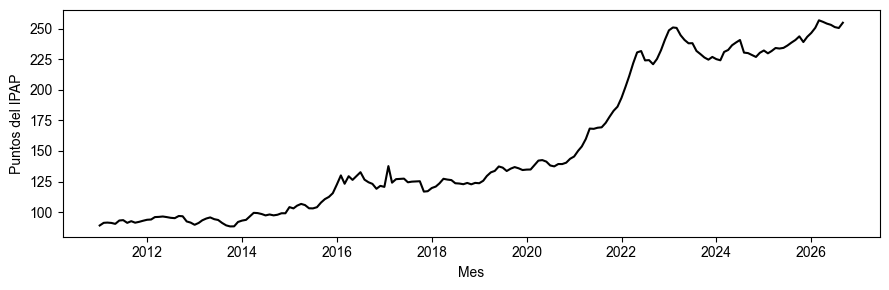

In [2]:
serie = cargar_datos()
print(f"{len(serie)} meses: {serie.index[0]} a {serie.index[-1]}")
display(serie.head(3).to_frame())
display(serie.tail(3).to_frame())
fig, eje = plt.subplots(figsize=(9,3))
eje.plot(serie.index.to_timestamp(), serie.to_numpy(), color="black")
eje.set(xlabel="Mes", ylabel="Puntos del IPAP")
fig.tight_layout()
plt.show()


## Separar el entrenamiento y la evaluación

Para pronosticar 2025 nos situamos en diciembre de 2024. El modelo solo recibe información hasta ese corte y utiliza los últimos 120 meses disponibles. Los doce valores reales de 2025 se guardan aparte para medir el error después.


In [3]:
origen = "2024-12"
historia = serie.loc[:origen]
entrenamiento = historia.iloc[-VENTANA:]
reales_2025 = serie.loc["2025-01":"2025-12"]
print(f"Entrenamiento: {len(entrenamiento)} meses, {entrenamiento.index[0]} a {entrenamiento.index[-1]}")
print(f"Evaluación: {len(reales_2025)} meses de 2025")


Entrenamiento: 120 meses, 2015-01 a 2024-12
Evaluación: 12 meses de 2025


## Ajustar ETS y pronosticar

ETS combina nivel, tendencia aditiva amortiguada y estacionalidad aditiva de doce meses. El ajuste estima sus parámetros dentro del entrenamiento. pronosticar aplica el límite de 120 meses y devuelve los doce meses siguientes sin actualizar con los datos reales intermedios. Se utiliza ExponentialSmoothing de statsmodels 0.14.6.


In [4]:
prediccion = pronosticar(historia)
comparacion = pd.DataFrame({"real_BMC":reales_2025,"prediccion_ETS":prediccion})
comparacion["error_real_menos_predicho"] = comparacion.real_BMC-comparacion.prediccion_ETS
display(comparacion.round(2))


,real_BMC,prediccion_ETS,error_real_menos_predicho
2025-01,232.07,231.80,0.27
2025-02,229.75,235.03,-5.28
2025-03,231.59,235.11,-3.52
2025-04,234.10,237.47,-3.37
2025-05,233.67,237.94,-4.27
2025-06,234.20,237.28,-3.08
2025-07,236.09,235.17,0.92
2025-08,238.49,231.73,6.76
2025-09,240.65,230.97,9.68
2025-10,243.62,230.89,12.73


## Comparar con reglas sencillas

Naive repite el último valor. Naive12 repite el mismo mes del año anterior. Deriva12 prolonga el cambio mensual medio del último año. Todos pronostican las mismas fechas. RMSE y MAE se expresan en puntos; MAPE en porcentaje. Un número menor indica menor error.


In [5]:
evaluacion_2025 = evaluar(serie,[origen])
display(metricas(evaluacion_2025).round(4))


,modelo,RMSE,MAE,MAPE,n
0,ETS_120_meses,7.1607,5.9443,2.4897,12
1,Naive,7.5855,6.2550,2.6136,12
2,Naive12,8.4915,7.1725,3.0056,12
3,Deriva12,5.5889,4.5181,1.8868,12


## Evaluar seis cortes

Usamos cortes de septiembre de 2020 a septiembre de 2025 y siempre generamos los doce meses posteriores. Son 72 objetivos por método. Los bloques evaluados no se superponen, pero los entrenamientos comparten historia. La comparación de 2025 comparte meses con estos bloques y no es otra prueba independiente.


In [6]:
bloques = evaluar(serie)
display(metricas(bloques).round(4))
por_corte = metricas(bloques,("origen","modelo"))
display(por_corte.pivot(index="origen",columns="modelo",values="RMSE").round(2))


,modelo,RMSE,MAE,MAPE,n
0,ETS_120_meses,13.6792,9.5049,4.6106,72
1,Naive,21.0601,14.9242,6.9929,72
2,Naive12,29.0127,22.0078,10.2963,72
3,Deriva12,14.1372,9.9139,4.7571,72


modelo,Deriva12,ETS_120_meses,Naive,Naive12
origen,,,,
2020-09,18.88,18.20,21.16,21.37
2021-09,20.80,24.50,40.52,52.85
2022-09,18.36,11.71,20.05,36.02
2023-09,5.18,5.31,5.55,13.19
2024-09,4.51,4.43,4.96,5.28
2025-09,5.09,2.57,10.67,17.36


## Leer el error por horizonte

El horizonte 1 es el primer mes después del corte y el horizonte 12 es el último de ese año. Cada horizonte reúne seis errores por método. La precisión del primer mes no representa la precisión del año completo.


In [7]:
por_horizonte = metricas(bloques,("modelo","horizonte"))
display(por_horizonte[por_horizonte.modelo=="ETS_120_meses"].round(2))


,modelo,horizonte,RMSE,MAE,MAPE,n
0,ETS_120_meses,1,2.29,2.06,0.98,6
1,ETS_120_meses,2,5.45,4.62,2.31,6
2,ETS_120_meses,3,7.43,5.21,2.61,6
3,ETS_120_meses,4,9.97,7.26,3.49,6
4,ETS_120_meses,5,10.99,9.30,4.43,6
5,ETS_120_meses,6,12.71,10.01,4.79,6
6,ETS_120_meses,7,14.05,9.08,4.49,6
7,ETS_120_meses,8,18.32,12.17,5.89,6
8,ETS_120_meses,9,18.50,13.31,6.35,6
9,ETS_120_meses,10,16.75,12.76,6.20,6


## Límites de la comparación

La captura puede incorporar revisiones. Sin versiones históricas no podemos reconstruir toda la información disponible en cada fecha. La ventana se definió durante el desarrollo sobre períodos ya examinados. Por eso la evaluación es retrospectiva y no garantiza precisión futura. La entrega contiene pronósticos centrales, sin intervalos calibrados.


## Guardar el ajuste y ver los gráficos

El modelo final utiliza 120 meses, de octubre de 2016 a septiembre de 2026. Sus predicciones cubren octubre de 2026 a septiembre de 2027 y no se incorporan al CSV oficial. El archivo PKL guarda el ajuste y permite usarlo sin entrenar otra vez. El programa principal genera las mismas tablas y figuras de este recorrido.


Modelo entrenado con 120 meses


,fecha,horizonte,prediccion
0,2026-10,1,255.73
1,2026-11,2,254.74
2,2026-12,3,257.37
3,2027-01,4,259.38
4,2027-02,5,262.87
5,2027-03,6,264.86
6,2027-04,7,267.19
7,2027-05,8,268.43
8,2027-06,9,268.18
9,2027-07,10,266.25


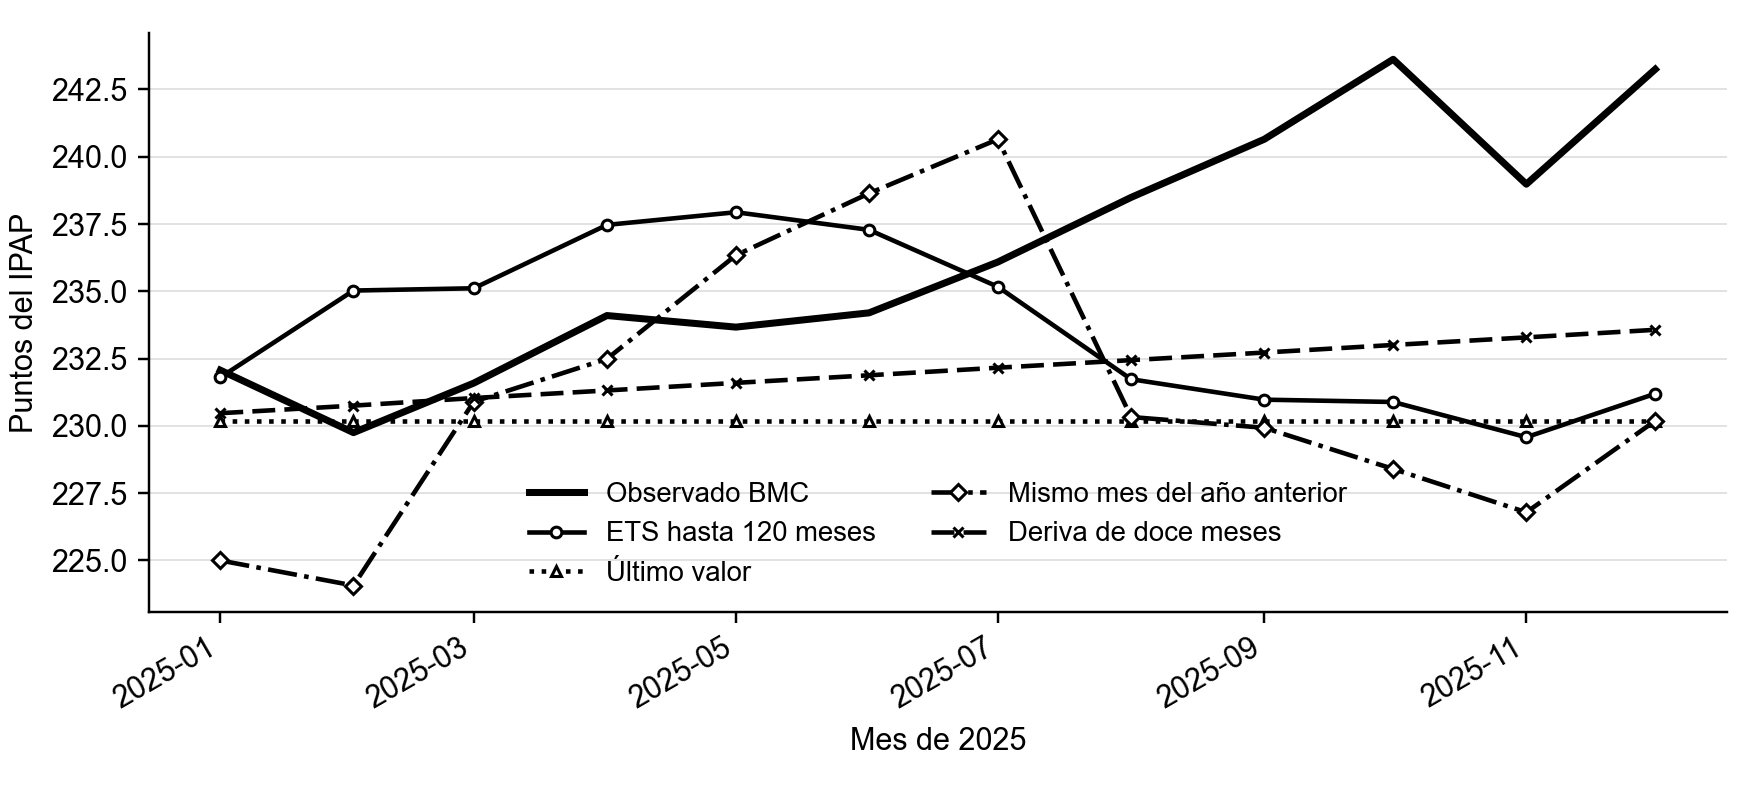

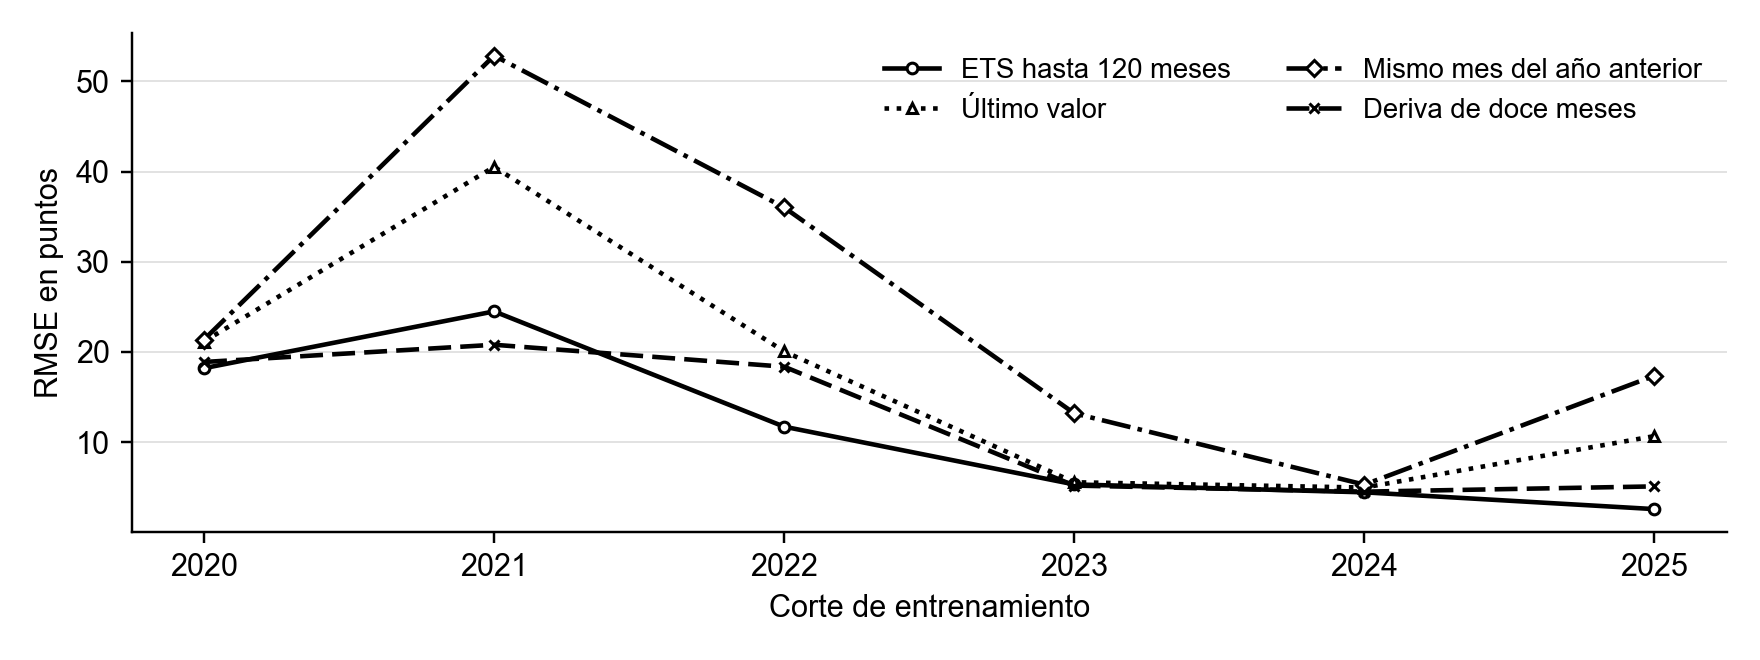

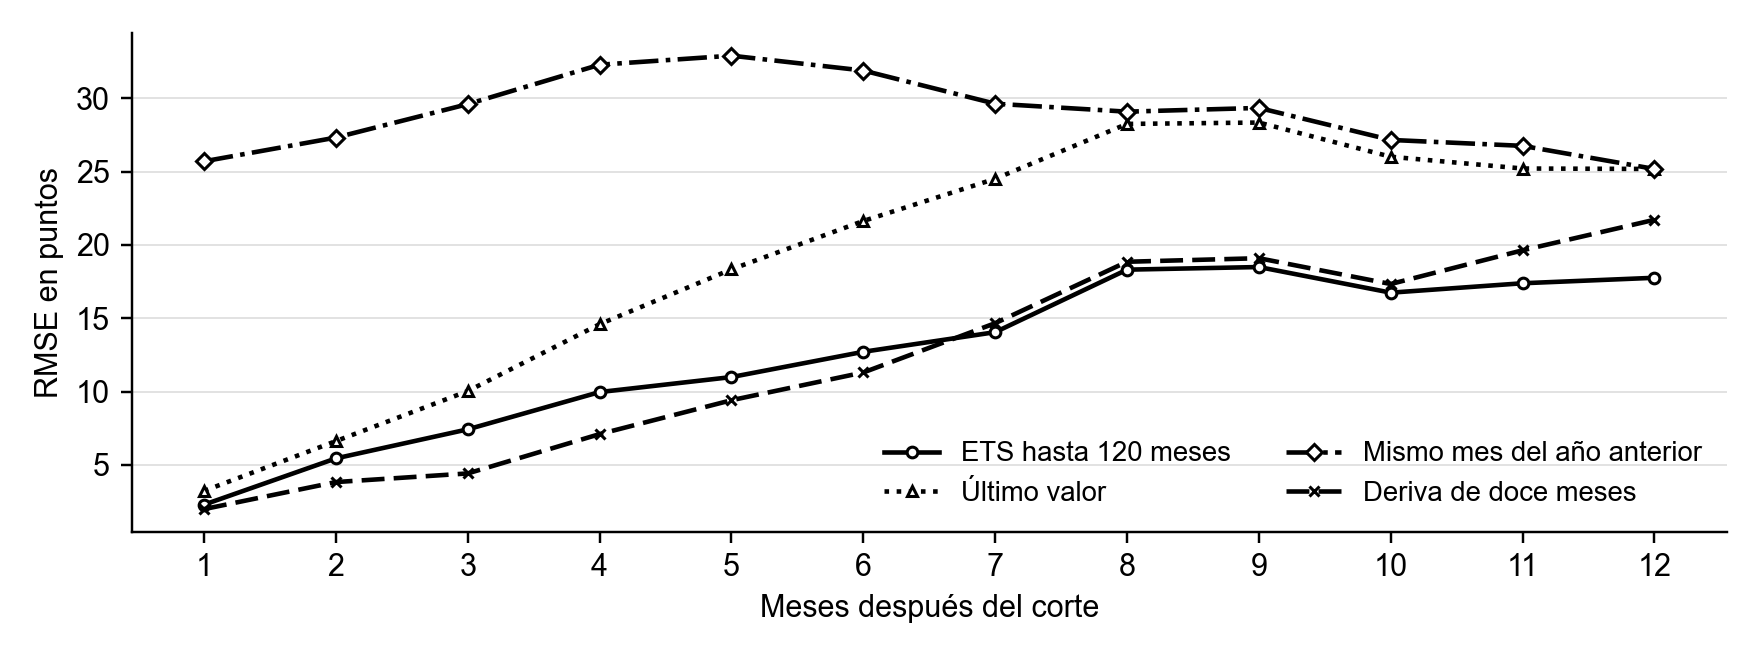

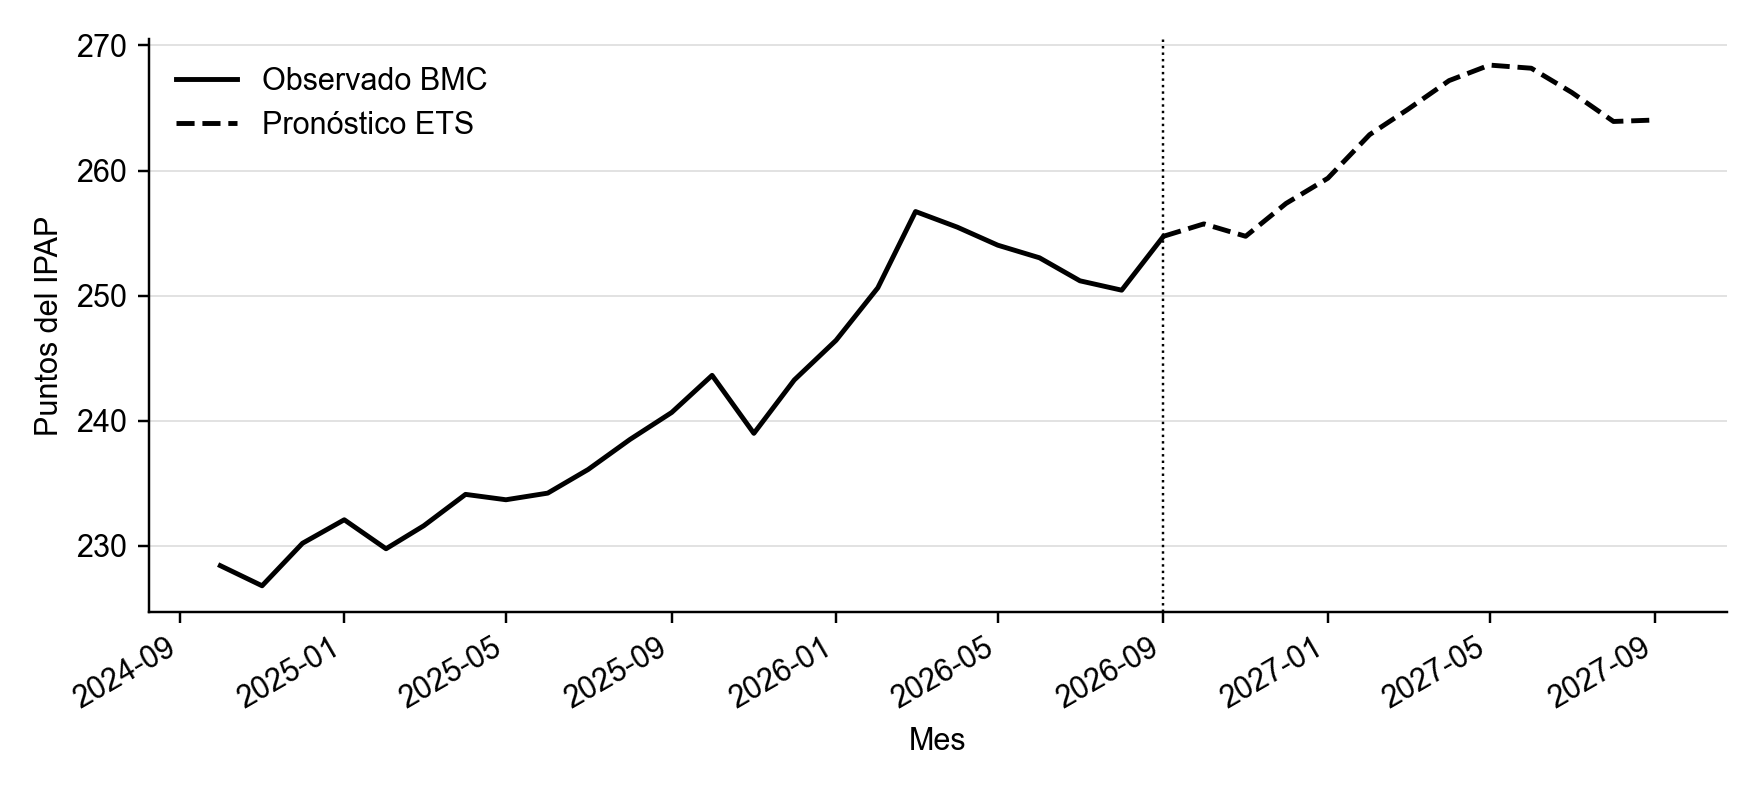

In [8]:
guardar_modelo(serie)
paquete = cargar_modelo()
futuro = pronostico_guardado(paquete)
futuro.to_csv(BASE/"resultados/pronostico_12_meses.csv",index=False)
graficar(serie,bloques,evaluacion_2025,futuro)
print(f"Modelo entrenado con {len(paquete["historia"])} meses")
display(futuro[["fecha","horizonte","prediccion"]].round(2))
for nombre in ["comparacion_2025.png","error_por_corte.png","error_por_horizonte.png","pronostico_12_meses.png"]:
    display(Image(filename=str(BASE/"resultados"/nombre)))
